# EDA 1 — Corpus científico do RAG (chunking e balanceamento)

**Épico 4.2 (#38) · RF-10, RNF-04, RNF-05, RNF-06**

Objetivos:
1. **Fundamentar o `chunk_size` com dados**: histograma de tokens por trecho e por seção, comparado com o limite do modelo de embeddings.
2. **Medir o balanceamento do corpus por característica atômica** do catálogo TDAH.

A análise usa os trechos que o `ingestao.py` do time de RAG já gera (`rag/iris-rag/pacote/chunks.jsonl`), sem refazer o corte.

> Pré-requisito: `chunks.jsonl` não é versionado. Se não existir, gere com `cd rag/iris-rag/pacote && python ingestao.py`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

from iris.eval import corpus_eda as eda

REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
print("Raiz do projeto:", ROOT)

Raiz do projeto: /Users/aluno1/Documents/Iris


## 1. Carga dos trechos e contagem de tokens

In [2]:
# "mpnet" ou "qwen3" = tokenizador REAL do modelo (precisa de `uv add transformers` e internet na 1ª vez).
# None = tiktoken (proxy aproximado).
TOKENIZADOR = "mpnet"

modelos = eda.embedding_models(ROOT / eda.EMBEDDINGS_REL)
limites = {k: v["max_tokens"] for k, v in modelos.items() if "max_tokens" in v}
print("Limites de tokens dos modelos (embeddings.py):", limites or "não encontrado")

raw, n_vazios = eda.drop_empty(eda.load_chunks(ROOT / eda.CHUNKS_REL))
print(f"{n_vazios} trechos vazios excluídos (ex.: placeholders de documentos sem texto distribuído)")

df, metodo = eda.add_tokens(raw, tokenizer_model=modelos[TOKENIZADOR]["nome"] if TOKENIZADOR else None)
print(f"{len(df)} trechos | {df['doc_id'].nunique()} documentos | método de tokens: {metodo}")
if metodo.startswith("aproxim"):
    print("⚠️ tiktoken indisponível: os números de tokens abaixo são ESTIMATIVAS. Rode com internet para o valor real.")

Limites de tokens dos modelos (embeddings.py): {'mpnet': 512, 'qwen3': 1024}
42 trechos vazios excluídos (ex.: placeholders de documentos sem texto distribuído)


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


1041 trechos | 32 documentos | método de tokens: tokenizador/sentence-transformers/paraphrase-multilingual-mpnet-base-v2


> **Atenção ao método:** `tiktoken` (cl100k) é um *proxy*. O modelo de embeddings usa o tokenizador dele, que pode contar diferente (no corpus do Íris, o `tiktoken` superestimou os tokens em português). Por isso a análise final usa o tokenizador real do modelo (`TOKENIZADOR`).

## 2. Tokens por trecho

,tokens (texto indexado),palavras
n,1041.0,1041.0
min,76.0,40.0
p50,351.0,202.0
p75,487.0,303.0
p90,554.0,338.0
p95,594.0,346.0
p99,761.0,357.0
max,839.0,511.0
media,350.8,201.4


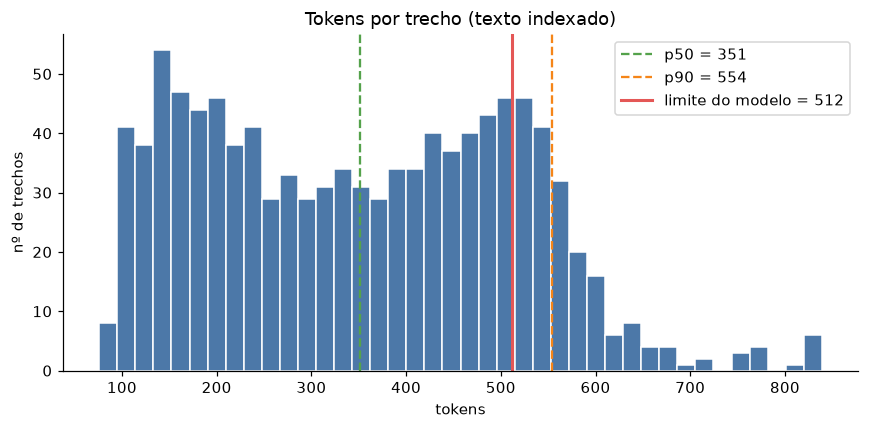

In [3]:
# Com tokenizador escolhido, vale o limite dele; senão, o menor limite (critério conservador).
MAX_TOKENS = limites.get(TOKENIZADOR) if TOKENIZADOR else (min(limites.values()) if limites else None)
rep = eda.chunk_size_report(df, MAX_TOKENS)

display(pd.DataFrame({"tokens (texto indexado)": rep["tokens_por_trecho"], "palavras": rep["palavras_por_trecho"]}))
fig = eda.plot_chunk_tokens(df, MAX_TOKENS, REPORTS / "eda1_tokens_trecho.png")

In [4]:
print("Tokens por palavra, por idioma:")
display(eda.tokens_per_word(df).to_frame("tokens/palavra"))
print(f"Razão geral: {rep['tokens_por_palavra']:.2f} tokens/palavra")

Tokens por palavra, por idioma:


,tokens/palavra
idioma,
en,1.74
pt-BR,1.74


Razão geral: 1.74 tokens/palavra


**Por que isso importa:** o limite atual do chunking é em **palavras** (350), mas o modelo de embeddings tem limite em **tokens**. A razão tokens/palavra faz a ponte entre os dois. Trechos acima do limite do modelo são truncados na indexação, e o conteúdo cortado deixa de ser recuperável.

## 3. Tokens por seção

600 seções (documento + seção)


,tokens por seção
count,600.0
mean,608.7
std,855.9
min,76.0
25%,184.5
50%,317.0
75%,746.8
max,12401.0


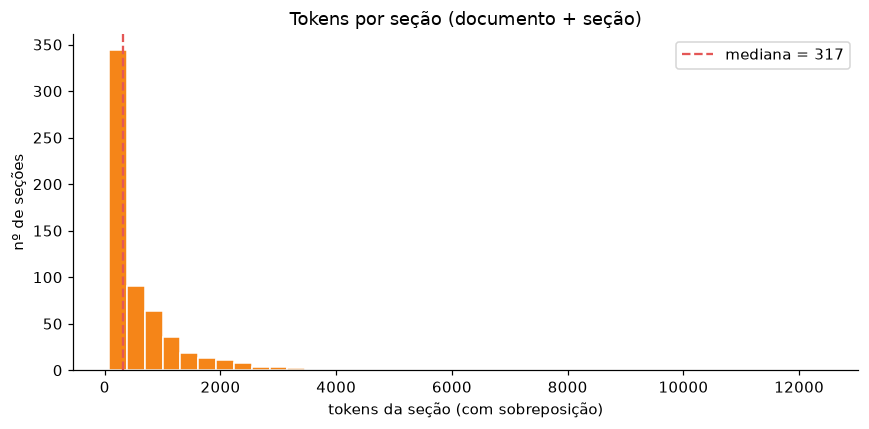

In [5]:
secoes = eda.section_table(df)
print(f"{len(secoes)} seções (documento + seção)")
display(secoes["tokens"].describe().round(1).to_frame("tokens por seção"))
fig = eda.plot_section_tokens(secoes, REPORTS / "eda1_tokens_secao.png")

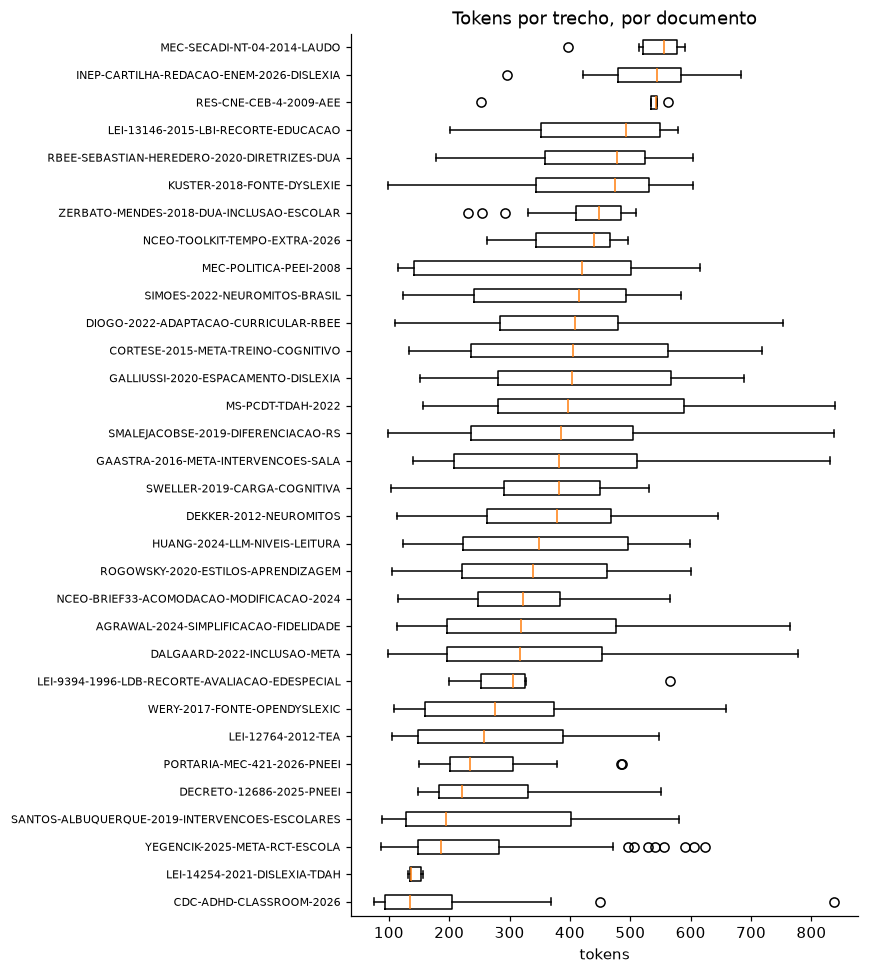

In [6]:
fig = eda.plot_tokens_by_doc(df, REPORTS / "eda1_tokens_documento.png")

Seções **menores** que um trecho cabem inteiras num chunk. Seções **maiores** são partidas, e aí a sobreposição entre vizinhos é o que preserva o contexto. A distribuição acima mostra quanto do corpus cai em cada situação.

## 4. Balanceamento por característica atômica

,id_caracteristica,nome,barreiras,n_trechos,n_docs
0,fadiga_executiva_autorregulacao_provas_extensas,Fadiga executiva e queda de sustentação atenci...,atencao_sustentada,377,9
1,atencao_sustentada_textos_longos,Fadiga de atenção sustentada em blocos textuai...,leitura_texto_longo,308,9
2,impulsividade_leitura_superficial_negacoes,Impulsividade na resposta e omissão de condiçõ...,controle_inibitorio,304,7
3,organizacao_sequencial_expressao_escrita,Dificuldade na organização sequencial de etapa...,organizacao_sequencial,295,6
4,distratibilidade_poluicao_visual_layout,Distratibilidade por poluição visual e element...,sobrecarga_visual,160,4
5,sobrecarga_memoria_trabalho_comandos_multiplos,Sobrecarga de memória de trabalho em comandos ...,memoria_trabalho,152,3
6,retencao_dados_intermediarios_problemas_multie...,Dificuldade na retenção e manipulação mental d...,memoria_trabalho,152,3
7,bloqueio_iniciacao_tarefas_abertas,Bloqueio na iniciação de tarefas abertas sem p...,iniciacao_tarefa,122,4
8,ritmo_processamento_pressao_temporal,Sobrecarga por velocidade de processamento sob...,velocidade_processamento,62,2
9,flexibilidade_cognitiva_alternancia_topicos,Rigidez na alternância entre tipos de tarefa o...,flexibilidade_cognitiva,14,1


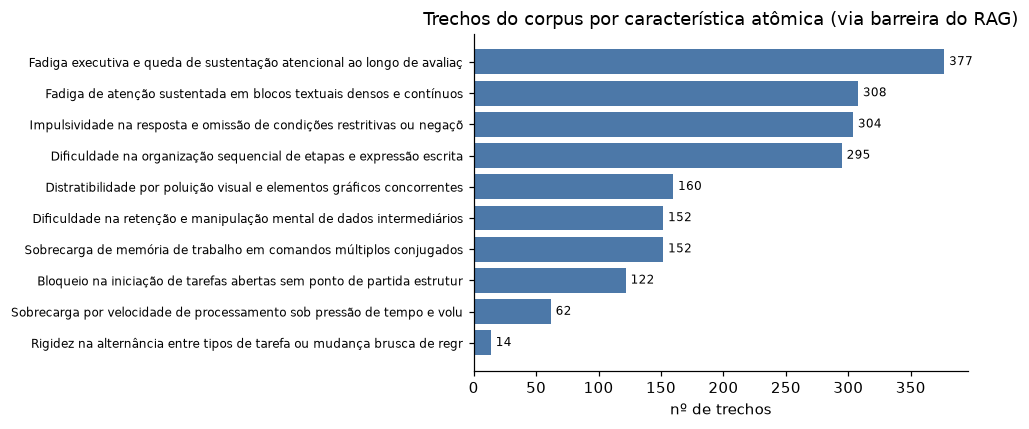

In [7]:
catalogo = eda.load_catalog(ROOT / eda.CATALOG_REL)
balanco = eda.barrier_balance(df, catalogo)
display(balanco)
fig = eda.plot_balance(balanco, REPORTS / "eda1_balanceamento_caracteristica.png")

In [8]:
diverg = eda.vocabulary_mismatch(df, catalogo)
print("Barreiras do catálogo SEM trechos no corpus:", diverg["so_no_catalogo"] or "nenhuma")
print("Barreiras nos trechos FORA do catálogo:     ", diverg["so_nos_trechos"] or "nenhuma")

sem_trechos = balanco.loc[balanco["n_trechos"] == 0, "nome"].tolist()
print("\nCaracterísticas sem nenhum trecho de apoio:", sem_trechos or "nenhuma")

Barreiras do catálogo SEM trechos no corpus: nenhuma
Barreiras nos trechos FORA do catálogo:      nenhuma

Características sem nenhum trecho de apoio: nenhuma


,trechos
parte,
A,76
B,269
C,144
D,552


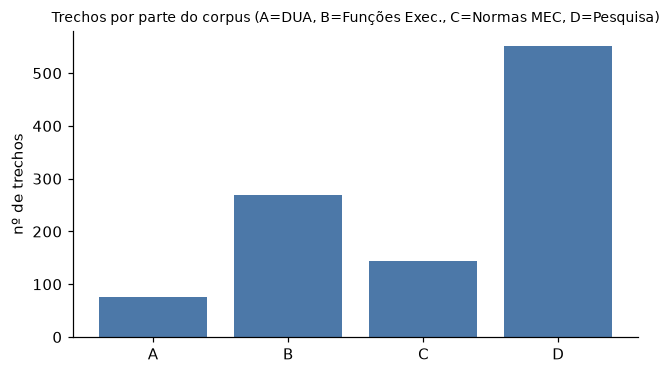

In [9]:
fig = eda.plot_balance_by_part(df, REPORTS / "eda1_balanceamento_parte.png")
display(df["parte"].value_counts().sort_index().to_frame("trechos") if "parte" in df else "sem coluna 'parte'")

**Como ler:** um trecho pode cobrir mais de uma barreira, então as contagens se sobrepõem. Características com poucos trechos têm pouco apoio para o RAG recuperar. Se uma característica aparece com **zero**, ou o corpus não cobre o tema, ou o nome da barreira no catálogo difere do usado nos trechos (veja o bloco de vocabulário acima).

## 5. Recomendação de `chunk_size` e resumo

In [10]:
rep = eda.chunk_size_report(df, MAX_TOKENS)
t, p = rep["tokens_por_trecho"], rep["palavras_por_trecho"]

print(f"Atual: máx. {rep['max_palavras_atual']} palavras por trecho (mediana {p['p50']}, p90 {p['p90']}, máx. {p['max']}).")
print(f"Em tokens: mediana {t['p50']}, p90 {t['p90']}, p99 {t['p99']}, máx. {t['max']}.")
if MAX_TOKENS:
    print(f"\nLimite do modelo: {MAX_TOKENS} tokens -> {rep['trechos_acima_do_limite']} trechos "
          f"({rep['pct_acima_do_limite']}%) acima do limite.")
    if rep["trechos_acima_do_limite"] == 0:
        print("✅ Nenhum trecho excede o limite: o chunk_size atual é compatível com o modelo.")
    else:
        print(f"⚠️ Um máximo de ~{rep['max_palavras_sugerido']} palavras manteria o trecho TÍPICO dentro do limite, com 10% de folga "
              f"para o prefixo de contexto (razão média {rep['tokens_por_palavra']:.2f} tokens/palavra). "
              f"Trechos com razão acima da média ainda podem passar: valide com o tokenizador do modelo.")

if MAX_TOKENS and "idioma" in df.columns:
    print("\nEstouro do limite por idioma:")
    display(eda.overflow_table(df, MAX_TOKENS, "idioma"))
    print("Máx. de palavras por trecho, por idioma (típico dentro do limite, 10% de folga):")
    print(rep["max_palavras_sugerido_por_idioma"])
    print("\nDocumentos com maior % de trechos acima do limite:")
    display(eda.overflow_table(df, MAX_TOKENS, "doc_id").head(10))
    fig = eda.plot_overflow_by_doc(df, MAX_TOKENS, REPORTS / "eda1_estouro_por_documento.png")

resumo = eda.run(ROOT, max_tokens=MAX_TOKENS, tokenizer=TOKENIZADOR)
print("\nArquivos gerados em", REPORTS)

Atual: máx. 350 palavras por trecho (mediana 202, p90 338, máx. 511).
Em tokens: mediana 351, p90 554, p99 761, máx. 839.

Limite do modelo: 512 tokens -> 201 trechos (19.3%) acima do limite.
⚠️ Um máximo de ~264 palavras manteria o trecho TÍPICO dentro do limite, com 10% de folga para o prefixo de contexto (razão média 1.74 tokens/palavra). Trechos com razão acima da média ainda podem passar: valide com o tokenizador do modelo.

Estouro do limite por idioma:


,idioma,n_trechos,acima,tokens_p90,pct_acima
0,pt-BR,315,74,556,23.5
1,en,726,127,549,17.5


Máx. de palavras por trecho, por idioma (típico dentro do limite, 10% de folga):
{'en': 264, 'pt-BR': 264}

Documentos com maior % de trechos acima do limite:


,doc_id,n_trechos,acima,tokens_p90,pct_acima
0,MEC-SECADI-NT-04-2014-LAUDO,6,5,584,83.3
1,RES-CNE-CEB-4-2009-AEE,5,4,555,80.0
2,INEP-CARTILHA-REDACAO-ENEM-2026-DISLEXIA,18,12,636,66.7
3,LEI-13146-2015-LBI-RECORTE-EDUCACAO,9,4,560,44.4
4,MS-PCDT-TDAH-2022,28,12,781,42.9
5,CORTESE-2015-META-TREINO-COGNITIVO,31,12,633,38.7
6,KUSTER-2018-FONTE-DYSLEXIE,34,11,555,32.4
7,RBEE-SEBASTIAN-HEREDERO-2020-DIRETRIZES-DUA,55,17,548,30.9
8,GALLIUSSI-2020-ESPACAMENTO-DISLEXIA,25,7,638,28.0
9,GAASTRA-2016-META-INTERVENCOES-SALA,44,11,592,25.0



Arquivos gerados em /Users/aluno1/Documents/Iris/reports


## 6. Limitações

- Com `TOKENIZADOR = None`, a contagem usa `tiktoken`: um proxy, não o tokenizador real do modelo. Os números finais devem vir com o tokenizador do modelo.
- A soma de tokens por seção inclui a sobreposição entre trechos vizinhos (limite superior).
- O balanceamento mede **cobertura**, não qualidade do conteúdo recuperado: isso é papel da avaliação de recall do RAG.
- Documentos sem licença aberta têm o texto fora do repositório (`rag/.gitignore`): quem não os tiver localmente vê um corpus menor.